<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula%203/%20MBA_DL_Aula3_01_demo_conceito_texto_em_numeros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 3 | Demo de conceito: como transformar palavras em números

**MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio**

Uma ideia por célula. Execute junto (`Shift+Enter`).

1. **Por que texto é difícil**: negação, ordem e ambiguidade em reviews reais.
2. **Sacola de palavras** em 10 linhas: a primeira forma de virar número.
3. **TF-IDF**: dar peso ao que é raro.
4. **Word2vec**: palavras viram vetores, e vetores têm aritmética.
5. **O limite**: uma palavra, um vetor só. O gancho para os Transformers.

Dados: reviews de produtos em português (B2W-Reviews01, Americanas.com, 2018, licença CC BY-NC-SA 4.0). Tudo está no repositório; nada é baixado.

In [2]:
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

cands = ["reviews_b2w_subset.csv", "../data/reviews_b2w_subset.csv", "data/reviews_b2w_subset.csv"]
caminho = next((c for c in cands if os.path.exists(c)), None)
if caminho is None:                                   # no Colab: abre o seletor de arquivos
    from google.colab import files
    print("Envie o arquivo reviews_b2w_subset.csv:")
    caminho = list(files.upload())[0]
df = pd.read_csv(caminho)
print(df.shape, "reviews |", df["sentimento"].value_counts().to_dict())
df[["review_title", "review_text", "overall_rating", "sentimento"]].head(5)

(30000, 8) reviews | {'negativo': 15000, 'positivo': 15000}


,review_title,review_text,overall_rating,sentimento
0,FIXAÇÃO 0!!!!,"COMPREI ESSE PERFUME DE 200 ML, ELEFANTE BRANC...",1,negativo
1,Insatisfação com parceiros da Americanas,Meu produto além de não vir com lacre na caixa...,1,negativo
2,Não vi diferença!,Achei q nao resolveu nada. Meu cachorro contin...,1,negativo
3,Ótimo produto,"Acabei de receber o celular, por enquanto nada...",4,positivo
4,produto ruim demais,comprei esse relógio e veio da distribuidora M...,1,negativo


## 1. Por que texto é difícil para a máquina

Três armadilhas que não existem em imagens. Reviews reais, sem edição.

In [3]:
pd.set_option("display.max_colwidth", 160)
def mostrar(mask, n=3, cols=("review_text", "overall_rating")):
    return df.loc[mask, list(cols)].head(n)

print("NEGAÇÃO: as mesmas palavras, sentido oposto")
display(mostrar(df["review_text"].str.contains(r"\bnão recomendo\b", case=False) & (df.sentimento == "negativo"), 2))
display(mostrar(df["review_text"].str.contains(r"\brecomendo\b", case=False) & ~df["review_text"].str.contains(r"\bnão recomendo\b", case=False) & (df.sentimento == "positivo"), 2))

NEGAÇÃO: as mesmas palavras, sentido oposto


,review_text,overall_rating
9,"muito fragil,a tampa não fecha pela fragilidade de suas repartições, são um quebra caebeça, pois desmonta e não afirma. não recomendo.",1
19,"Comprei a cafeteira pelo parceiro EFacil. O produto veio com defeito, não solta água. Entrei em contato com as Americanas, onde me encaminharam para o SAC d...",1


,review_text,overall_rating
13,"Estou muito satisfeito, recomendo.Produto de altíssima qualidade, a marca fala por si.",4
21,Produto bom emtrega antes do prazo.amei e super recomendo,5


In [4]:
print("AMBIGUIDADE: 'nota' é nota fiscal ou nota 10?")
display(mostrar(df["review_text"].str.contains(r"nota fiscal", case=False), 2))
display(mostrar(df["review_text"].str.contains(r"nota (?:10|dez|mil)", case=False), 2))

AMBIGUIDADE: 'nota' é nota fiscal ou nota 10?


,review_text,overall_rating
10,"O produto começou a vazar com 1 mês de uso, a Polar simplesmente manda uma nota fiscal com telefones que não existem e as Americanas não estão nem ai, 1 hor...",1
18,"Comprei o produto em dezembro, previsto para entregar 14 de fevereiro. Ate agora nao recebi nem a nota fiscal do produto",1


,review_text,overall_rating
56,"Compacta e eficiente, adorei a lavadora. Lava e centrífuga muito bem. Como sempre Americanas nota 10. Entrega antes do prazo.",5
445,"smartphone j5 prime maravilhoso super recomendo, produto chegou dentro do prazo combinado, nota 10.",5


In [5]:
print("ORDEM: trocar a ordem muda o sentido, mas as palavras são as mesmas")
a = "o produto chegou antes do prazo"
b = "o prazo chegou antes do produto"
print(sorted(a.split()) == sorted(b.split()), "<- mesma sacola de palavras")

ORDEM: trocar a ordem muda o sentido, mas as palavras são as mesmas
True <- mesma sacola de palavras


## 2. Sacola de palavras em 10 linhas

A ideia mais simples: ignore a ordem, conte as palavras. Cada frase vira um vetor com o número de vezes que cada palavra aparece.
Troque as frases abaixo pelas da turma.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

frases = ["gostei muito do produto, chegou rápido",
          "não gostei do produto, chegou atrasado",
          "produto bom, entrega rápida",
          "entrega atrasada e produto com defeito"]

cv = CountVectorizer()
X = cv.fit_transform(frases)
sacola = pd.DataFrame(X.toarray(), columns=cv.get_feature_names_out(), index=[f"frase {i+1}" for i in range(len(frases))])
sacola

,atrasada,atrasado,bom,chegou,com,defeito,do,entrega,gostei,muito,não,produto,rápida,rápido
frase 1,0,0,0,1,0,0,1,0,1,1,0,1,0,1
frase 2,0,1,0,1,0,0,1,0,1,0,1,1,0,0
frase 3,0,0,1,0,0,0,0,1,0,0,0,1,1,0
frase 4,1,0,0,0,1,1,0,1,0,0,0,1,0,0


Repare: a frase 1 e a frase 2 diferem em duas colunas (`não`, `atrasado` em vez de `rápido`). Para a sacola, elas são 80% iguais. Para o cliente, são opostas.

⏱ **Checkpoint 1:** a tabela apareceu com uma coluna por palavra?

## 3. TF-IDF: dar peso ao que é raro

Contar não basta: "produto" aparece em quase todo review e não diz nada. **TF-IDF** multiplica a contagem por um fator que cresce quando a palavra é rara no conjunto.
Vamos medir no corpus inteiro quais palavras pesam pouco e quais pesam muito.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(min_df=5)
Xt = tfidf.fit_transform(df["review_text"])
idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("Vocabulário:", len(idf), "palavras")
print("\nMenor peso (aparecem em quase todo review):", idf.head(12).index.tolist())
print("\nExemplos de peso alto (raras, informativas):", idf.loc[["defeito", "estorno", "arranhado", "trincada", "reembolso"]].round(2).to_dict())

Vocabulário: 6543 palavras

Menor peso (aparecem em quase todo review): ['produto', 'de', 'não', 'que', 'muito', 'com', 'do', 'um', 'para', 'recomendo', 'no', 'da']

Exemplos de peso alto (raras, informativas): {'defeito': 4.49, 'estorno': 6.19, 'arranhado': 7.62, 'trincada': 8.91, 'reembolso': 6.42}


In [8]:
# o mesmo review visto por contagem e por TF-IDF: quais palavras ganham destaque?
i = int(df.index[df["review_text"].str.contains("defeito", case=False)][0])
linha = Xt[i].toarray().ravel()
top = pd.Series(linha, index=tfidf.get_feature_names_out()).sort_values(ascending=False).head(8)
print(df.loc[i, "review_text"][:300], "\n")
print("Palavras com maior peso TF-IDF neste review:")
print(top.round(3).to_string())

Comprei a cafeteira pelo parceiro EFacil. O produto veio com defeito, não solta água. Entrei em contato com as Americanas, onde me encaminharam para o SAC do EFacil. Abri a ocorrência e a troca do meu produto foi NEGADA porque tinha passado de 7 dias da entrega (e menos de 30!!).  NÃO RECOMENDO O PA 

Palavras com maior peso TF-IDF neste review:
parceiro        0.374
encaminharam    0.288
ocorrência      0.275
cafeteira       0.218
sac             0.217
solta           0.214
passado         0.211
abri            0.200


## 4. Word2vec: palavras viram vetores, e vetores têm aritmética

Em 2013, o word2vec mostrou que dá para aprender um vetor por palavra olhando só os **vizinhos** dela em milhões de frases. Palavras usadas em contextos parecidos ficam com vetores parecidos.

O arquivo `word2vec_reviews_pt.npz` tem vetores de 100 dimensões aprendidos a partir dos 132 mil reviews do corpus completo (treino de 15 segundos em CPU). Nenhum dicionário foi usado: só o texto dos clientes.

In [10]:
cands_w2v = ["word2vec_reviews_pt.npz", "../data/word2vec_reviews_pt.npz", "data/word2vec_reviews_pt.npz"]
caminho_w2v = next((c for c in cands_w2v if os.path.exists(c)), None)
if caminho_w2v is None:                               # no Colab: abre o seletor de arquivos
    from google.colab import files
    print("Envie o arquivo word2vec_reviews_pt.npz:")
    caminho_w2v = list(files.upload())[0]
w2v = np.load(caminho_w2v)
vocab, V = [str(w) for w in w2v["vocab"]], w2v["vetores"]
V = V / np.linalg.norm(V, axis=1, keepdims=True)          # normaliza: produto escalar vira cosseno
idx = {w: i for i, w in enumerate(vocab)}
print(len(vocab), "palavras, cada uma com", V.shape[1], "números. Por exemplo, 'entrega' =", V[idx["entrega"]][:6].round(3), "...")

def vizinhos(palavra, n=6, vetor=None):
    v = V[idx[palavra]] if vetor is None else vetor / np.linalg.norm(vetor)
    sims = V @ v
    ordem = np.argsort(-sims)
    return [(vocab[j], round(float(sims[j]), 2)) for j in ordem if vocab[j] != palavra][:n]

for w in ["entrega", "péssimo", "bateria", "atendimento", "garantia"]:
    print(f"{w:<12} ->", vizinhos(w))

13607 palavras, cada uma com 100 números. Por exemplo, 'entrega' = [ 0.015 -0.033  0.085  0.062  0.013 -0.041] ...
entrega      -> [('entregue', 0.62), ('chegada', 0.59), ('entraga', 0.59), ('envio', 0.55), ('entrga', 0.55), ('entega', 0.53)]
péssimo      -> [('pessimo', 0.79), ('horrível', 0.77), ('ruim', 0.61), ('horrivel', 0.58), ('central', 0.56), ('eletrônico', 0.53)]
bateria      -> [('câmera', 0.7), ('carga', 0.67), ('camera', 0.63), ('memória', 0.6), ('câmara', 0.57), ('tela', 0.55)]
atendimento  -> [('serviço', 0.78), ('vendedor', 0.66), ('fornecedor', 0.57), ('compromisso', 0.56), ('parceiro', 0.56), ('comprometimento', 0.56)]
garantia     -> [('assistência', 0.54), ('assistencia', 0.51), ('anatel', 0.51), ('conserto', 0.5), ('autorizada', 0.49), ('china', 0.47)]


Três coisas para notar:
- `entrega` tem como vizinhos `entraga` e `entrga`: o modelo aprendeu os **erros de digitação dos clientes** como sinônimos. Ninguém programou isso.
- `bateria` vizinha de `câmera`, `carga`, `memória`: o modelo aprendeu o que é uma "característica de celular".
- `garantia` vizinha de `assistência` e `conserto`: aprendeu o que acontece quando o produto quebra.

In [11]:
def analogia(a, menos, mais, n=4):
    v = V[idx[a]] - V[idx[menos]] + V[idx[mais]]
    return [w for w, _ in vizinhos(a, n=n + 3, vetor=v) if w not in (a, menos, mais)][:n]

print("ótimo  - bom    + ruim  =", analogia("ótimo", "bom", "ruim"))
print("rápida - rápido + lento =", analogia("rápida", "rápido", "lento"))
print("péssima - péssimo + ótimo =", analogia("péssima", "péssimo", "ótimo"))

ótimo  - bom    + ruim  = ['horrível', 'péssimo', 'péssima', 'horrivel']
rápida - rápido + lento = ['lenta', 'demorada', 'confusa', 'instável']
péssima - péssimo + ótimo = ['ótima', 'excelente', 'boa', 'alta']


A aritmética funciona porque o espaço aprendeu direções: "intensidade negativa", "gênero gramatical". Isso é o que uma **camada de embedding** faz dentro de qualquer rede de linguagem, inclusive nos LLMs.

⏱ **Checkpoint 2:** `ótimo - bom + ruim` deu algo como `horrível` ou `péssimo` para você?

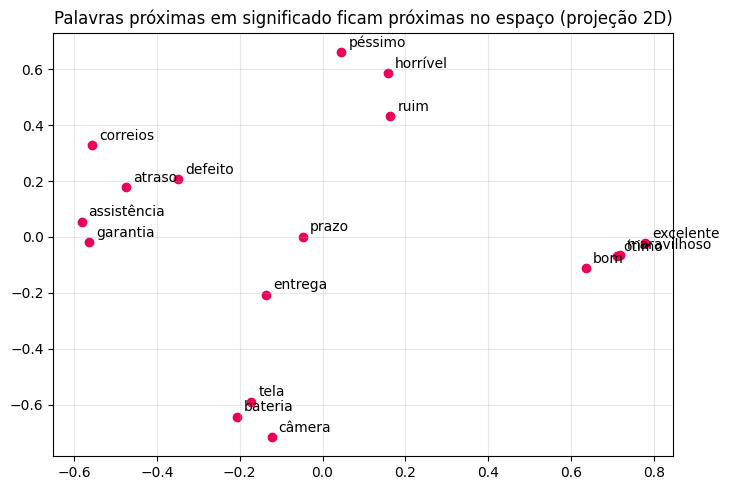

In [12]:
# Visualizar: 2 dimensões de um espaço de 100 (projeção com PCA)
from sklearn.decomposition import PCA
palavras = ["ótimo", "excelente", "maravilhoso", "bom", "ruim", "péssimo", "horrível",
            "entrega", "prazo", "correios", "atraso", "bateria", "tela", "câmera", "garantia", "assistência", "defeito"]
P = PCA(2).fit_transform(np.stack([V[idx[w]] for w in palavras]))
plt.figure(figsize=(8, 5.5))
plt.scatter(P[:, 0], P[:, 1], color="#EB005A")
for (x, y), w in zip(P, palavras): plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=10)
plt.title("Palavras próximas em significado ficam próximas no espaço (projeção 2D)"); plt.grid(alpha=.3); plt.show()

## 5. O limite: uma palavra, um vetor só

`nota` aparece nos reviews com dois sentidos: *nota fiscal* e *nota 10*. O word2vec tem **um** vetor para `nota`. Veja os vizinhos:

In [13]:
print("vizinhos de 'nota':", vizinhos("nota", 8))
print()
print("Mas os clientes usam 'nota' assim:")
for t in df.loc[df["review_text"].str.contains(r"nota (?:10|dez)", case=False), "review_text"].head(2): print(" -", t[:140])
for t in df.loc[df["review_text"].str.contains(r"nota fiscal", case=False), "review_text"].head(2): print(" -", t[:140])

vizinhos de 'nota': [('nf', 0.62), ('fiscal', 0.51), ('anota', 0.51), ('emissão', 0.48), ('emitida', 0.48), ('emitiu', 0.47), ('zero', 0.44), ('cupom', 0.44)]

Mas os clientes usam 'nota' assim:
 - Compacta e eficiente, adorei a lavadora. Lava e centrífuga muito bem. Como sempre Americanas nota 10. Entrega antes do prazo.
 - smartphone j5 prime maravilhoso super recomendo, produto chegou dentro do prazo combinado, nota 10.
 - O produto começou a vazar com 1 mês de uso, a Polar simplesmente manda uma nota fiscal com telefones que não existem e as Americanas não est
 - Comprei o produto em dezembro, previsto para entregar 14 de fevereiro. Ate agora nao recebi nem a nota fiscal do produto


O vetor de `nota` ficou com o sentido mais frequente (nota fiscal). O sentido "nota 10" se perdeu. Em uma frase, a palavra deveria significar uma coisa; em outra, outra. **O contexto precisa mudar o vetor.** Isso é exatamente o que a atenção dos Transformers faz, tema da parte 4 desta aula.

## O que levar desta demo

| Conceito | Em uma frase |
|---|---|
| Sacola de palavras | Contar palavras ignorando a ordem. Simples, forte, cego para negação. |
| TF-IDF | Pesar mais o que é raro. O baseline de qualquer projeto de texto. |
| Embedding (word2vec) | Um vetor por palavra, aprendido pelos vizinhos. Tem aritmética e absorve até erros de digitação. |
| Limite do embedding estático | Uma palavra, um vetor. O contexto não entra. |

**Próximo notebook:** usar isso para classificar o sentimento de 30 mil reviews, com um baseline TF-IDF e uma rede LSTM.